# 第 28 章：鞅与测度

本章每一个算例，全部重新算一遍，图 28.2 重新生成，本章关于测度的每一个论断也都变得可见：同一个价格在三种计价单位下相同，Girsanov 定理就是对模拟路径重新加权，$N(d_1)$ 与 $N(d_2)$ 是同一个事件在两种单位下的计数。每一个数字都与书里印出的数值并排打印，因此任何数字一旦偏离书中的值，都能一眼看出，而不会悄悄出错。

| 小节 | 复现的内容 | 例 |
|---|---|---|
| 1 | 两个风险的市场价格不能不同 | 28.1 |
| 2 | 两步树上的 Radon–Nikodym 导数及其密度过程 | 28.2 |
| 3 | 一份看涨期权，三种计价单位，一个价格 | — |
| 4 | Girsanov：对路径重新加权移动的是均值而不是离散程度；图 28.2 | — |
| 5 | $N(d_1)$ 与 $N(d_2)$：同一个事件，两个概率 | 28.3 |
| 6 | 不同相关系数下 Margrabe 的交换期权 | — |
| 7 | 计价单位何时失效：现金结算的互换期权 | — |

第 1–3 节和各个闭式解都是精确的。第 4–6 节另做模拟，目的是让测度变换实际发生，而不是计算闭式解算不出的东西；这些数字都附有标准误差，并标明是模拟值。随机种子是固定的，因此重新运行会印出相同的数字。

用 NumPy、SciPy 与 Matplotlib。

表头保留英文：中文字符在等宽终端里是双宽的，而 Python 的 `%-46s` 按字符数计。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import exp, log, sqrt
from scipy.integrate import quad
from scipy.stats import norm

N, phi = norm.cdf, norm.pdf
BAD = []
rng = np.random.default_rng(2028)

# 本书的配色，取自 preamble.tex：主序列用 exampleframe，对照序列用 snapshotframe。
# 各序列同时以线型和颜色区分，因为本书以灰度印刷。
BLUE, AMBER = "#28466E", "#78551E"
plt.rcParams.update({"figure.figsize": (6.4, 3.4), "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})


def show(label, got, printed, tol=5e-4):
    """把算出来的值印在本章所印的值旁边。`tol` 是绝对误差。"""
    ok = abs(got - printed) <= tol
    if not ok:
        BAD.append(label)
    print("%-46s %12.6f   book %11.6f   %s" % (label, got, printed, "ok" if ok else "DIFFERS"))


def simulated(label, mean, se, exact):
    """蒙特卡洛估计值与闭式解并列，附标准误差。"""
    print("%-46s %12.6f   s.e. %.6f   closed form %.6f   (simulated)" % (label, mean, se, exact))

## 1. 两个风险的市场价格不能不同：例 28.1

由同一个 $dW$ 驱动的两个资产，每单位波动率必须提供相同的超额收益率。若 A 提供 0.25、B 提供 0.20，就持有 1 美元 A、$-1.3333$ 美元 B：$dW$ 项相互抵消，建仓带来 0.3333 美元现金，按 3% 投资，每年无风险地赚得 A 持仓金额的 1.00%。

下面的模拟让这个组合沿一千条随机路径运行。每条路径的终值都相同，这就是*无风险*的含义，而这个终值正是例中算出的 1%。

In [2]:
R1 = 0.03
MU_A, SIG_A, MU_B, SIG_B = 0.08, 0.20, 0.06, 0.15
lam_a, lam_b = (MU_A - R1) / SIG_A, (MU_B - R1) / SIG_B
w = -SIG_A / SIG_B                             # 每单位 A 所需、使 dW 抵消的 B 的数量
show("market price of risk, A", lam_a, 0.25, 1e-12)
show("market price of risk, B", lam_b, 0.20, 1e-12)
show("units of B per unit of A", w, -1.3333, 5e-5)
show("portfolio cost", 1 + w, -0.3333, 5e-5)
show("riskless profit, % of A's notional a year",
     100 * (MU_A + w * MU_B - R1 * (1 + w)), 1.00, 5e-3)
show("mu_B that lambda = 0.25 forces, %", 100 * (R1 + 0.25 * SIG_B), 6.75, 1e-9)

# 每日再平衡一年：持有 1 美元 A 与 w 美元 B，现金 -(1 + w) 按 r 计息
steps, paths = 252, 1000
dt = 1.0 / steps
dW = rng.standard_normal((paths, steps)) * sqrt(dt)
pnl = np.zeros(paths)
for k in range(steps):
    pnl += (MU_A * dt + SIG_A * dW[:, k]) + w * (MU_B * dt + SIG_B * dW[:, k]) - R1 * (1 + w) * dt
print()
print("一年、每日再平衡、1,000 条路径：每 1 美元 A 的盈亏")
print("  均值 %.6f   最小 %.6f   最大 %.6f" % (pnl.mean(), pnl.min(), pnl.max()))

market price of risk, A                            0.250000   book    0.250000   ok
market price of risk, B                            0.200000   book    0.200000   ok
units of B per unit of A                          -1.333333   book   -1.333300   ok
portfolio cost                                    -0.333333   book   -0.333300   ok
riskless profit, % of A's notional a year          1.000000   book    1.000000   ok
mu_B that lambda = 0.25 forces, %                  6.750000   book    6.750000   ok

一年、每日再平衡、1,000 条路径：每 1 美元 A 的盈亏
  均值 0.010000   最小 0.010000   最大 0.010000


## 2. 两步树上的 Radon–Nikodym 导数：例 28.2

节点是固定的；随测度改变的只有分支概率。真实世界的 $p = 0.65$ 是一个假设，风险中性的 $q$ 则由树强制确定，两者在各节点上的比值就是 $\Lambda = dQ/dP$。这套理论建立在三个事实之上：$E^P[\Lambda] = 1$，且每个值都为正；好的状态被调低权重，坏的状态被调高，因为 $p > q$ 说明股票带有风险溢价；在 $Q$ 下，贴现后的股价是一个鞅。

密度过程 $\Lambda_t = E^P[\Lambda \mid \mathcal{F}_t]$ 是逐步比值的连乘：上行一步乘以 $q/p$，下行一步乘以 $(1-q)/(1-p)$；根据迭代期望定律，它是一个 $P$-鞅。用错误的测度为看涨期权定价，价格会错三分之一。

In [3]:
S0, U, R2, P_UP = 100.0, 1.2, 0.04, 0.65
D = 1 / U
q = (exp(R2) - D) / (U - D)
show("risk-neutral probability q", q, 0.565848, 5e-7)

NODES = {"dd": (S0 * D * D, (1 - P_UP) ** 2, (1 - q) ** 2),
         "ud": (S0, 2 * P_UP * (1 - P_UP), 2 * q * (1 - q)),
         "uu": (S0 * U * U, P_UP ** 2, q ** 2)}
PRINTED = {"dd": (69.4444, 0.122500, 0.188488, 1.538680),
           "ud": (100.0000, 0.455000, 0.491328, 1.079842),
           "uu": (144.0000, 0.422500, 0.320183, 0.757831)}
print("%6s %10s %10s %10s %10s" % ("node", "S(2)", "P", "Q", "Lambda"))
for k, (s, pp, qq) in NODES.items():
    print("%6s %10.4f %10.6f %10.6f %10.6f" % (k, s, pp, qq, qq / pp))
    show("  %s: Lambda" % k, qq / pp, PRINTED[k][3], 5e-7)
show("E_P[Lambda]", sum(qq for _, pp, qq in NODES.values()), 1.0, 1e-12)
show("e^{-2r} E_Q[S(2)], a martingale", exp(-2 * R2) * sum(s * qq for s, _, qq in NODES.values()), 100.0, 5e-5)
show("e^{-2r} E_P[S(2)], the risk premium", exp(-2 * R2) * sum(s * pp for s, pp, _ in NODES.values()), 106.02, 5e-3)
print()
lam_up, lam_dn = q / P_UP, (1 - q) / (1 - P_UP)
show("Lambda_1 at the up node, q/p", lam_up, 0.870535, 5e-7)
show("Lambda_1 at the down node, (1-q)/(1-p)", lam_dn, 1.240436, 5e-7)
show("  = P-average of the open paths' Lambda",
     P_UP * NODES["uu"][2] / NODES["uu"][1] + (1 - P_UP) * NODES["ud"][2] / NODES["ud"][1], lam_up, 1e-12)
show("E_P[Lambda_1], the tower property", P_UP * lam_up + (1 - P_UP) * lam_dn, 1.0, 1e-12)
print()
call_p = exp(-2 * R2) * sum(max(s - 100, 0) * pp for s, pp, _ in NODES.values())
call_q = exp(-2 * R2) * sum(max(s - 100, 0) * qq for s, _, qq in NODES.values())
show("call under P, the wrong measure", call_p, 17.160733, 5e-6)
show("call under Q", call_q, 13.004930, 5e-6)
show("error from the wrong measure, %", 100 * (call_p / call_q - 1), 32.0, 0.05)

risk-neutral probability q                         0.565848   book    0.565848   ok
  node       S(2)          P          Q     Lambda
    dd    69.4444   0.122500   0.188488   1.538680
  dd: Lambda                                       1.538680   book    1.538680   ok
    ud   100.0000   0.455000   0.491328   1.079842
  ud: Lambda                                       1.079842   book    1.079842   ok
    uu   144.0000   0.422500   0.320183   0.757831
  uu: Lambda                                       0.757831   book    0.757831   ok
E_P[Lambda]                                        1.000000   book    1.000000   ok
e^{-2r} E_Q[S(2)], a martingale                  100.000000   book  100.000000   ok
e^{-2r} E_P[S(2)], the risk premium              106.017092   book  106.020000   ok

Lambda_1 at the up node, q/p                       0.870535   book    0.870535   ok
Lambda_1 at the down node, (1-q)/(1-p)             1.240436   book    1.240436   ok
  = P-average of the open paths' Lambda

## 3. 一份看涨期权，三种计价单位，一个价格

计价单位变换定理说，计价单位的选择改变测度，却从不改变价格。在例 28.2 的树上，这可以手算验证。以货币市场账户为计价单位，上行概率为 $q$。以股票为计价单位，上行概率为 $q^S = q\,u\,e^{-r}$，因为密度就是股票相对于账户的增长。以两年期零息债券为计价单位、利率不变时，上行概率仍是 $q$，因为这只债券与账户之比是确定的。每个测度都使各自的比值成为鞅，三者都给出 13.004930。

股票测度下的价格同时也是对 $N(d_1)$ 的初步认识：看涨期权中交付股票的那一半，等于 $S_0$ 乘以在 $Q^S$ 下期权以实值到期的概率。

In [4]:
q_s = q * U * exp(-R2)                         # 以股票为计价单位时的上行概率
paths = {"uu": (2, 0), "ud": (1, 1), "dd": (0, 2)}
mult = {"uu": 1, "ud": 2, "dd": 1}


def prob(k, up):
    n_up, n_dn = paths[k]
    return mult[k] * up ** n_up * (1 - up) ** n_dn


payoff = {k: max(NODES[k][0] - 100.0, 0.0) for k in NODES}
bank = exp(-2 * R2) * sum(payoff[k] * prob(k, q) for k in NODES)
stock = S0 * sum(payoff[k] / NODES[k][0] * prob(k, q_s) for k in NODES)
bond = exp(-2 * R2) * sum(payoff[k] / 1.0 * prob(k, q) for k in NODES)   # P(2,2) = 1
show("numeraire = money market account", bank, 13.004930, 5e-6)
show("numeraire = the stock", stock, 13.004930, 5e-6)
show("numeraire = the two-year zero-coupon bond", bond, 13.004930, 5e-6)
show("E^S[1] = 1 under the stock measure", sum(prob(k, q_s) for k in NODES), 1.0, 1e-12)
print()
in_money = [k for k in NODES if NODES[k][0] > 100.0]
share_leg = S0 * sum(prob(k, q_s) for k in in_money)
cash_leg = 100.0 * exp(-2 * R2) * sum(prob(k, q) for k in in_money)
print("看涨期权 = 股票端 - 现金端 = %.6f - %.6f = %.6f" % (share_leg, cash_leg, share_leg - cash_leg))
print("Q^S(实值) = %.6f，Q(实值) = %.6f：同一个事件，两种单位"
      % (sum(prob(k, q_s) for k in in_money), sum(prob(k, q) for k in in_money)))

numeraire = money market account                  13.004930   book   13.004930   ok
numeraire = the stock                             13.004930   book   13.004930   ok
numeraire = the two-year zero-coupon bond         13.004930   book   13.004930   ok
E^S[1] = 1 under the stock measure                 1.000000   book    1.000000   ok

看涨期权 = 股票端 - 现金端 = 42.561589 - 29.556659 = 13.004930
Q^S(实值) = 0.425616，Q(实值) = 0.320183：同一个事件，两种单位


## 4. Girsanov：均值移动，离散程度不变（图 28.2）

在连续时间下，例 28.2 的树对应 $\sigma = \ln 1.2 = 18.23\%$，由其 $p$ 得到漂移 $\mu = 7.13\%$，因此 $\lambda = (\mu - r)/\sigma = 0.1718$。把测度从 $P$ 换成 $Q$，对数收益率的均值下移 $\lambda\sigma T$，标准差不变。这就是图 28.2。

下面的模拟把测度变换实际做一遍。在 $P$ 下抽取路径，以 $\Lambda_T = \exp(-\lambda W_T - \lambda^2 T/2)$ 为每条路径加权，再重新计算各阶矩。加权后的均值落在风险中性均值上，标准差则不动。每条路径实现的二次变差在两个测度下也完全相同，因为重新加权改变的是哪些路径更可能出现，而从不改变路径本身。

tree's implied sigma                               0.182322   book    0.182300   ok
tree's implied mu                                  0.071317   book    0.071300   ok
lambda = (mu - r) / sigma                          0.171768   book    0.171800   ok
mean log return under P                            0.109393   book    0.109400   ok
mean log return under Q                            0.046759   book    0.046800   ok
sd of the log return, both                         0.257842   book    0.257800   ok
separation lambda sigma T                          0.062634   book    0.062600   ok



E_P[Lambda_T]                                      1.000031   s.e. 0.000552   closed form 1.000000   (simulated)
mean log return, unweighted (P)                    0.109406   s.e. 0.000577   closed form 0.109393   (simulated)
mean log return, weighted by Lambda (Q)            0.046670   s.e. 0.000587   closed form 0.046759   (simulated)
对数收益率的标准差：未加权 0.2580，加权 0.2581，闭式解 0.2578（模拟值）
ln S 的二次变差：平均 0.0665，sigma^2 T = 0.0665，逐条路径都相同


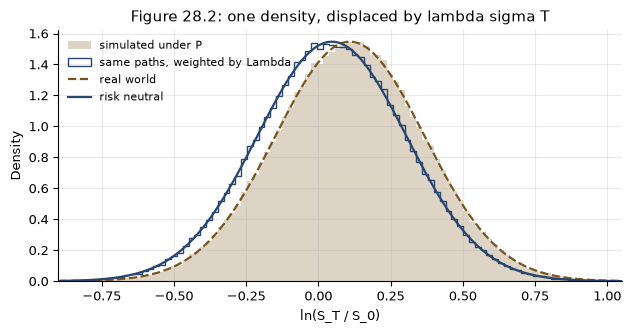

In [5]:
T4 = 2.0
sig4 = log(U)                                  # u = e^{sigma sqrt(dt)}，dt = 1
mu4 = P_UP * log(U) + (1 - P_UP) * log(D) + sig4 ** 2 / 2
lam4 = (mu4 - R2) / sig4
show("tree's implied sigma", sig4, 0.1823, 5e-5)
show("tree's implied mu", mu4, 0.0713, 5e-5)
show("lambda = (mu - r) / sigma", lam4, 0.1718, 5e-5)
m_p, m_q, sd = (mu4 - sig4 ** 2 / 2) * T4, (R2 - sig4 ** 2 / 2) * T4, sig4 * sqrt(T4)
show("mean log return under P", m_p, 0.1094, 5e-4)
show("mean log return under Q", m_q, 0.0468, 5e-4)
show("sd of the log return, both", sd, 0.2578, 5e-4)
show("separation lambda sigma T", m_p - m_q, 0.0626, 5e-4)
print()

n, steps = 200000, 100
dWp = rng.standard_normal((n, steps)) * sqrt(T4 / steps)          # P 下的布朗运动增量
x = (mu4 - sig4 ** 2 / 2) * T4 + sig4 * dWp.sum(axis=1)          # P 下的对数收益率
qv = (sig4 * dWp) ** 2                                            # 实现的二次变差
lam_T = np.exp(-lam4 * dWp.sum(axis=1) - 0.5 * lam4 ** 2 * T4)    # 每条路径上的 dQ/dP
wts = lam_T / lam_T.mean()
mean_q = float((wts * x).mean())
sd_q = sqrt(float((wts * (x - mean_q) ** 2).mean()))
simulated("E_P[Lambda_T]", lam_T.mean(), lam_T.std() / sqrt(n), 1.0)
simulated("mean log return, unweighted (P)", x.mean(), x.std() / sqrt(n), m_p)
simulated("mean log return, weighted by Lambda (Q)", mean_q, (wts * x).std() / sqrt(n), m_q)
print("对数收益率的标准差：未加权 %.4f，加权 %.4f，闭式解 %.4f（模拟值）"
      % (x.std(), sd_q, sd))
print("ln S 的二次变差：平均 %.4f，sigma^2 T = %.4f，逐条路径都相同"
      % (qv.sum(axis=1).mean(), sig4 ** 2 * T4))

z = np.linspace(-0.9, 1.05, 300)
fig, ax = plt.subplots()
ax.hist(x, bins=120, density=True, color=AMBER, alpha=0.25, label="simulated under P")
ax.hist(x, bins=120, density=True, weights=wts, histtype="step", color=BLUE, lw=1.0,
        label="same paths, weighted by Lambda")
ax.plot(z, norm.pdf(z, m_p, sd), "--", color=AMBER, lw=1.6, label="real world")
ax.plot(z, norm.pdf(z, m_q, sd), "-", color=BLUE, lw=1.6, label="risk neutral")
ax.set_xlim(-0.9, 1.05)
ax.set_xlabel("ln(S_T / S_0)"); ax.set_ylabel("Density")
ax.set_title("Figure 28.2: one density, displaced by lambda sigma T")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

## 5. $N(d_1)$ 与 $N(d_2)$：同一个事件，两个概率（例 28.3）

把看涨期权拆成股票端和现金端。现金端需要以实值到期的风险中性概率 $N(d_2)$。股票端以股票为计价单位定价，需要的是*同一个事件*在股票测度下的概率 $N(d_1)$。对这份虚值期权，两者分别为 39.19% 和 52.73%：以股票计，它以实值到期的可能性大于一半。

下面的模拟抽取一组风险中性路径，把以实值到期的路径数两遍：一遍直接计数，一遍以股票测度的密度 $S_T e^{-rT}/S_0$ 为每条路径加权。

In [6]:
S5, K5, R5, SIG5, T5 = 100.0, 110.0, 0.04, 0.28, 1.5
d1 = (log(S5 / K5) + (R5 + SIG5 ** 2 / 2) * T5) / (SIG5 * sqrt(T5))
d2 = d1 - SIG5 * sqrt(T5)
show("d1", d1, 0.068498, 5e-7)
show("d2", d2, -0.274431, 5e-7)
show("N(d1), the stock-measure probability", N(d1), 0.527305, 5e-7)
show("N(d2), the risk-neutral probability", N(d2), 0.391877, 5e-7)
show("call value", S5 * N(d1) - K5 * exp(-R5 * T5) * N(d2), 12.1344, 5e-5)
show("gap, percentage points", 100 * (N(d1) - N(d2)), 13.5, 0.05)
show("sigma sqrt(T)", SIG5 * sqrt(T5), 0.3429, 5e-5)
print()
z = rng.standard_normal(1000000)
ST = S5 * np.exp((R5 - SIG5 ** 2 / 2) * T5 + SIG5 * sqrt(T5) * z)
itm = (ST > K5).astype(float)
dens = ST * exp(-R5 * T5) / S5                 # dQ^S / dQ
simulated("Q(S_T > K), plain count", itm.mean(), itm.std() / 1000, N(d2))
simulated("Q^S(S_T > K), weighted by S_T e^{-rT}/S0", (dens * itm).mean(), (dens * itm).std() / 1000, N(d1))

d1                                                 0.068498   book    0.068498   ok
d2                                                -0.274431   book   -0.274431   ok
N(d1), the stock-measure probability               0.527305   book    0.527305   ok
N(d2), the risk-neutral probability                0.391877   book    0.391877   ok
call value                                        12.134407   book   12.134400   ok
gap, percentage points                            13.542851   book   13.500000   ok
sigma sqrt(T)                                      0.342929   book    0.342900   ok

Q(S_T > K), plain count                            0.391768   s.e. 0.000488   closed form 0.391877   (simulated)
Q^S(S_T > K), weighted by S_T e^{-rT}/S0           0.527150   s.e. 0.000681   closed form 0.527305   (simulated)


## 6. 用一个资产交换另一个资产：Margrabe

以资产 2 为计价单位，用资产 2 换取资产 1 的期权，就变成以比值 $S_1/S_2$ 为标的、执行价为 1 的看涨期权；这个比值是无漂移的鞅，波动率为 $\sqrt{\sigma_1^2 + \sigma_2^2 - 2\rho\sigma_1\sigma_2}$。利率不出现。交易台能观察到的输入（利率）不影响价格；它观察不到的输入（相关系数）决定价格：$\rho = 0.5$ 时为 10.52，0 时为 14.31，$-0.5$ 时为 17.25。

下面的模拟不借助计价单位变换，直接定价：两个相关资产，风险中性测度，执行价随之变动。结果一致，模拟中所用的利率也恰好约掉。最后一项检验是特例：令资产 2 为 $K$ 份零息债券，Margrabe 公式就变成布莱克–斯科尔斯–默顿公式。

sigma_G at rho = 0.5, %                           26.457513   book   26.460000   ok
exchange option at rho = +0.5                     10.524316   book   10.520000   ok
exchange option at rho = +0.0                     14.306533   book   14.310000   ok
exchange option at rho = -0.5                     17.252799   book   17.250000   ok
two-asset simulation, rho 0.5, r = 0%             10.507114   s.e. 0.028061   closed form 10.524316   (simulated)
two-asset simulation, rho 0.5, r = 8%             10.507114   s.e. 0.028061   closed form 10.524316   (simulated)
Margrabe with S2 = K e^{-rT}, sigma_2 = 0          9.625358   book    9.625358   ok


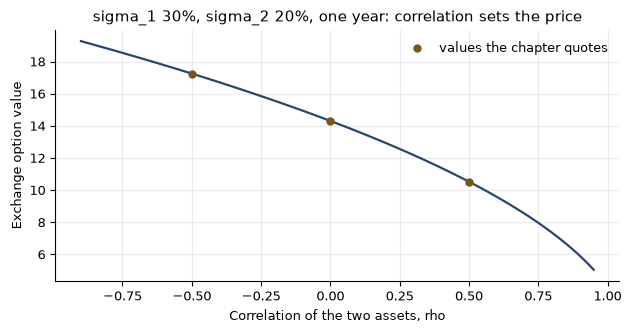

In [7]:
def margrabe(s1, s2, v1, v2, rho, T):
    """式 (28.13) 与式 (28.14)。"""
    v = sqrt(v1 ** 2 + v2 ** 2 - 2 * rho * v1 * v2)
    a = (log(s1 / s2) + v ** 2 * T / 2) / (v * sqrt(T))
    return s1 * N(a) - s2 * N(a - v * sqrt(T)), v


show("sigma_G at rho = 0.5, %", 100 * margrabe(100, 100, 0.30, 0.20, 0.5, 1.0)[1], 26.46, 5e-3)
for rho, want in ((0.5, 10.52), (0.0, 14.31), (-0.5, 17.25)):
    show("exchange option at rho = %+.1f" % rho, margrabe(100, 100, 0.30, 0.20, rho, 1.0)[0], want, 5e-3)

z1, z2 = rng.standard_normal((2, 400000))
for r_sim in (0.0, 0.08):                      # 利率取任何值都会约掉
    rho = 0.5
    w2 = rho * z1 + sqrt(1 - rho ** 2) * z2
    s1 = 100 * np.exp(r_sim - 0.045 + 0.30 * z1)
    s2 = 100 * np.exp(r_sim - 0.020 + 0.20 * w2)
    pay = exp(-r_sim) * np.maximum(s1 - s2, 0)
    simulated("two-asset simulation, rho 0.5, r = %.0f%%" % (100 * r_sim), pay.mean(),
              pay.std() / sqrt(len(pay)), margrabe(100, 100, 0.30, 0.20, 0.5, 1.0)[0])

K6, R6 = 110.0, 0.04                           # 资产 2 = K 份零息债券：sigma_2 = 0
bsm = 100 * N((log(100 / K6) + (R6 + 0.045) * 1.0) / 0.30) - K6 * exp(-R6) * N((log(100 / K6) + (R6 - 0.045)) / 0.30)
show("Margrabe with S2 = K e^{-rT}, sigma_2 = 0", margrabe(100, K6 * exp(-R6), 0.30, 1e-12, 0.0, 1.0)[0], bsm, 1e-8)

rhos = np.linspace(-0.9, 0.95, 120)
fig, ax = plt.subplots()
ax.plot(rhos, [margrabe(100, 100, 0.30, 0.20, r_, 1.0)[0] for r_ in rhos], "-", color=BLUE, lw=1.6)
ax.plot([-0.5, 0, 0.5], [17.25, 14.31, 10.52], "o", color=AMBER, ms=5, label="values the chapter quotes")
ax.set_xlabel("Correlation of the two assets, rho"); ax.set_ylabel("Exchange option value")
ax.set_title("sigma_1 30%, sigma_2 20%, one year: correlation sets the price")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 7. 计价单位何时失效：现金结算的互换期权

平价收益率现金结算惯例用一个关于互换利率的公式作年金来为互换期权估值，这个公式不是一组债券的组合，因此不能与真正的年金计价单位相互约掉。它随利率上升而下降：对十年期年付互换，从互换利率 2% 时的 8.98 降到 6% 时的 7.36，恰在支付方期权支付最多处最小。

把年金映射函数冻结在常数 $1/\tilde{A}(S_0)$，价格就变成对服从对数正态分布的互换利率做一次积分。积分留下的协方差，在 25% 的波动率下，从 66 个基点的权利金中扣去约 9.9 个基点，占 15%；在 40% 时占 28%。这是一个凸性项，因此它比权利金增长得更快。

A~(2%)                                             8.982585   book    8.980000   ok
A~(6%)                                             7.360087   book    7.360000   ok
premium at 25% vol, bp                            66.043615   book   66.000000   ok
  equals Black at the money, bp                   66.043615   book   66.043615   ok
covariance at 25% vol, bp                          9.917825   book    9.900000   ok
  as a share of the premium, %                    15.017084   book   15.000000   ok
share at 40% vol, %                               27.908479   book   28.000000   ok


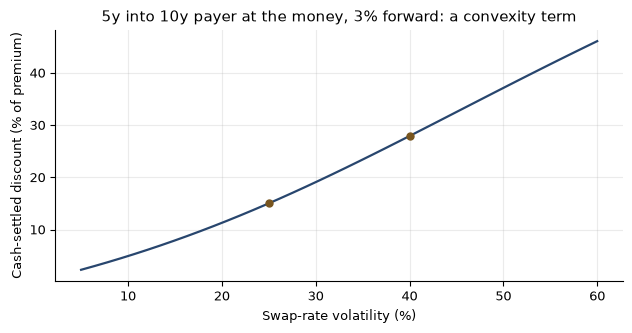

In [8]:
def cash_annuity(s, n=10):
    """十年期年付互换的平价收益率年金 A~(s)。"""
    i = np.arange(1, n + 1)
    return float(np.sum((1 + s) ** -i))


show("A~(2%)", cash_annuity(0.02), 8.98, 5e-3)
show("A~(6%)", cash_annuity(0.06), 7.36, 5e-3)


def cash_settled(F, vol, T):
    """每单位年金的权利金，以及现金年金留下的协方差。"""
    sd = vol * sqrt(T)
    S = lambda z: F * exp(sd * z - 0.5 * sd ** 2)
    z0 = 0.5 * sd                              # 支付方期权收益的折点，即 S = F 处
    prem = quad(lambda z: (S(z) - F) * phi(z), z0, 12)[0]
    cov = quad(lambda z: (S(z) - F) * (1 - cash_annuity(S(z)) / cash_annuity(F)) * phi(z), z0, 12)[0]
    return prem, cov


prem, cov = cash_settled(0.03, 0.25, 5.0)
show("premium at 25% vol, bp", 1e4 * prem, 66.0, 0.05)
show("  equals Black at the money, bp", 1e4 * 0.03 * (2 * N(0.25 * sqrt(5.0) / 2) - 1), 1e4 * prem, 1e-6)
show("covariance at 25% vol, bp", 1e4 * cov, 9.9, 0.05)
show("  as a share of the premium, %", 100 * cov / prem, 15.0, 0.5)
p40, c40 = cash_settled(0.03, 0.40, 5.0)
show("share at 40% vol, %", 100 * c40 / p40, 28.0, 0.5)

vols = np.linspace(0.05, 0.6, 40)
fig, ax = plt.subplots()
ax.plot(100 * vols, [100 * c / p for p, c in (cash_settled(0.03, v, 5.0) for v in vols)], "-",
        color=BLUE, lw=1.6)
ax.plot([25, 40], [100 * cov / prem, 100 * c40 / p40], "o", color=AMBER, ms=5)
ax.set_xlabel("Swap-rate volatility (%)"); ax.set_ylabel("Cash-settled discount (% of premium)")
ax.set_title("5y into 10y payer at the money, 3% forward: a convexity term")
plt.tight_layout(); plt.show()

## 重算的结论与两点收获

若下面一格报告每个数字都一致，本笔记本就与本章一致。

有两个习惯值得养成。**选一个能让收益中难处理的部分约掉的计价单位**：看涨期权的股票端用股票，交换期权用资产 2，互换期权用年金。价格不变（第 3 节已用三种方式说明），难度却变了。以及**约不掉时，剩下的就是一个协方差**，这里的现金结算互换期权是这样，第 30 章的每一项调整也是这样。

In [9]:
if BAD:
    print("有 %d 个数字与正文不符：" % len(BAD))
    for b in BAD:
        print("   ", b)
else:
    print("本笔记本中的每个数字都与正文一致")

本笔记本中的每个数字都与正文一致
